# Informe de personal — hazlo tú

**Nombre: Francisco Javier Porta Borge**  
**Fecha: 03 / 11 / 2026**  

Piloto de Matplotlib. La dirección de una empresa de servicios digitales quiere revisar la política salarial y la carga de trabajo. Tu informe debe ayudarle a decidir.

- **Trabajo:** en pareja.
- **Entrega:** individual, un cuaderno por estudiante.
- **Valoración:** hecho / no hecho; no se corrige el acierto.
- **Ficha completa:** [caso-informe-personal.md](caso-informe-personal.md).

No hay que descargar datos: se generan en la celda siguiente. Son datos sintéticos y no representan personas reales.


## 0. Preparación

Ejecuta la celda una vez. Comprueba que el kernel pertenece al entorno de visualización que has elegido. Si falla un import, anota el error y revisa el entorno; no instales en el Python del sistema.

Los datos tienen 240 empleados y 12 meses. La semilla fija permite repetir el mismo resultado.


In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(sys.executable)
print('pandas:', pd.__version__, '| Matplotlib:', matplotlib.__version__)
plt.style.use('default')

rng = np.random.default_rng(42)
n = 240
departamentos = np.array(['Datos'] * 60 + ['Web'] * 60 + ['Sistemas'] * 60 + ['Soporte'] * 60)
base = {'Datos': 2900, 'Web': 2500, 'Sistemas': 2700, 'Soporte': 2200}

experiencia = rng.integers(0, 26, n)
salario = np.array([base[d] for d in departamentos]) + 45 * experiencia + rng.normal(0, 250, n)
idx_atipicos = rng.choice(n, 8, replace=False)
salario[idx_atipicos] *= rng.uniform(2.2, 3.2, len(idx_atipicos))

edad = np.clip(22 + experiencia + rng.integers(0, 10, n), 22, 64)
horas_semana = rng.normal(40, 3, n).round(1)
satisfaccion = rng.normal(7, 1.5, n).clip(1, 10).round(1)
satisfaccion[rng.choice(n, 12, replace=False)] = np.nan

empleados = pd.DataFrame({
    'id': np.arange(1, n + 1),
    'departamento': departamentos,
    'edad': edad,
    'experiencia': experiencia,
    'salario': salario.round(2),
    'horas_semana': horas_semana,
    'satisfaccion': satisfaccion,
})

mensual = pd.DataFrame({
    'mes': np.arange(1, 13),
    'proyectos': [9, 10, 11, 12, 13, 12, 10, 9, 12, 14, 15, 17],
    'soporte': [12, 11, 13, 12, 14, 15, 13, 12, 16, 18, 21, 23],
    'horas_extra': [6, 5, 7, 6, 9, 10, 8, 7, 12, 15, 19, 22],
})

salida = Path('salidas_estaticas')
salida.mkdir(exist_ok=True)

print('Empleados:', empleados.shape, '| ausentes en satisfaccion:', empleados['satisfaccion'].isna().sum())
print('Meses:', len(mensual))
assert empleados.shape == (240, 7)
assert empleados['satisfaccion'].isna().sum() == 12
assert len(mensual) == 12
empleados.head()

c:\Users\ia\Desktop\IABD\.venv\Scripts\python.exe
pandas: 3.0.6 | Matplotlib: 3.11.2
Empleados: (240, 7) | ausentes en satisfaccion: 12
Meses: 12


,id,departamento,edad,experiencia,salario,horas_semana,satisfaccion
0,1,Datos,31,2,3390.44,42.0,5.3
1,2,Datos,46,20,3740.16,43.3,7.7
2,3,Datos,40,17,3409.13,41.1,7.1
3,4,Datos,35,11,3439.82,39.1,7.8
4,5,Datos,41,11,3450.00,41.4,6.7


## Situación 1 — Evolución mensual

**Pregunta:** ¿cómo ha cambiado la carga de trabajo a lo largo del año?

**Tarea:** con `mensual`, crea `fig_lineas, ax_lineas = plt.subplots(...)` y dibuja `proyectos` y `soporte` frente a `mes`. Usa dos líneas con marcadores distintos, leyenda, título y ejes con unidades. No uses `plt.plot` directamente.

**Salida esperada:** 12 meses y dos series; el soporte alcanza su máximo en diciembre.

**Cuando termines, ejecuta la celda de comprobación.** Si falla, revisa los nombres de las variables y las etiquetas.


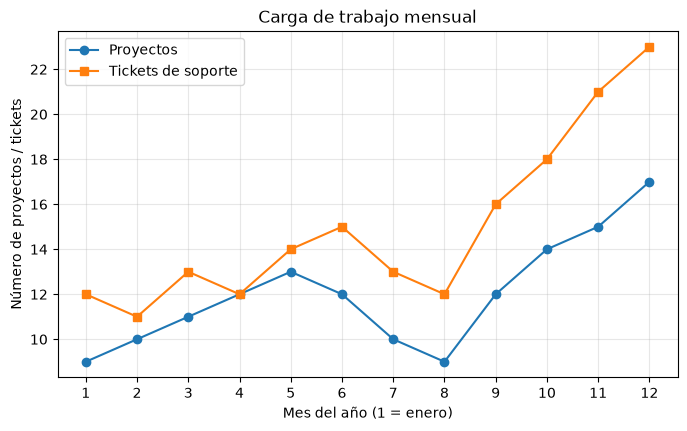

In [2]:
fig_lineas, ax_lineas = plt.subplots(figsize=(8, 4.5))
ax_lineas.plot(mensual['mes'], mensual['proyectos'], marker='o', label='Proyectos')
ax_lineas.plot(mensual['mes'], mensual['soporte'], marker='s', label='Tickets de soporte')
ax_lineas.set_xticks(mensual['mes'])
ax_lineas.set_title('Carga de trabajo mensual')
ax_lineas.set_xlabel('Mes del año (1 = enero)')
ax_lineas.set_ylabel('Número de proyectos / tickets')
ax_lineas.legend()
ax_lineas.grid(alpha=0.3)
plt.show()


In [3]:
assert len(mensual) == 12
assert mensual.loc[mensual['soporte'].idxmax(), 'mes'] == 12
assert 'fig_lineas' in globals() and 'ax_lineas' in globals()
assert len(ax_lineas.lines) >= 2
assert ax_lineas.get_legend() is not None
print('Situación 1: comprobación superada')

Situación 1: comprobación superada


## Situación 2 — Salario por departamento

**Pregunta:** ¿qué departamento cobra más y qué medida lo representa mejor?

**Tarea:** calcula `medias` y `medianas` del salario por departamento con `groupby`. Crea `fig_salarios, ax_salarios = plt.subplots(...)` y dibuja barras agrupadas con ambas medidas. Añade título, unidades y leyenda.

La media puede verse afectada por los salarios extremos; la mediana no.

**Salida esperada:** cuatro departamentos; Datos tiene la mediana más alta y su media supera a la mediana por los valores extremos.


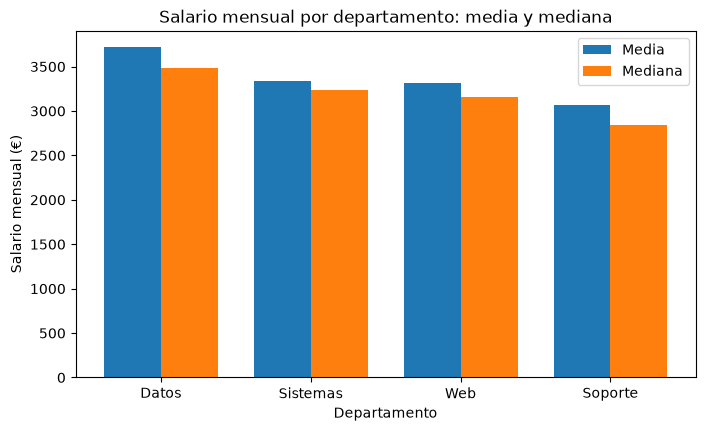

In [4]:
medias = empleados.groupby('departamento')['salario'].mean()
medianas = empleados.groupby('departamento')['salario'].median()
orden = ['Datos', 'Sistemas', 'Web', 'Soporte']
medias, medianas = medias[orden], medianas[orden]

fig_salarios, ax_salarios = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(orden))
ancho = 0.38
ax_salarios.bar(x - ancho / 2, medias.values, ancho, label='Media')
ax_salarios.bar(x + ancho / 2, medianas.values, ancho, label='Mediana')
ax_salarios.set_xticks(x)
ax_salarios.set_xticklabels(orden)
ax_salarios.set_title('Salario mensual por departamento: media y mediana')
ax_salarios.set_xlabel('Departamento')
ax_salarios.set_ylabel('Salario mensual (€)')
ax_salarios.legend()
plt.show()


In [5]:
assert set(medias.index) == {'Datos', 'Web', 'Sistemas', 'Soporte'}
assert set(medianas.index) == set(medias.index)
assert medianas['Datos'] > medianas['Soporte']
assert len(fig_salarios.axes) == 1
assert len(ax_salarios.patches) >= 8
assert ax_salarios.get_legend() is not None
print('Situación 2: comprobación superada')

Situación 2: comprobación superada


## Situación 3 — Distribución y valores extremos

**Pregunta:** ¿cómo se distribuye el salario y hay valores extremos por departamento?

**Tarea:** crea `fig_distribucion, axs_distribucion = plt.subplots(1, 2, ...)`.

- Izquierda: histograma con `bins=12` y `density=False`.
- Derecha: boxplot del salario por departamento. Construye `grupos` en el orden de `nombres` y rotula con `set_xticks`.

**Salida esperada:** cuatro cajas; algunos puntos por encima de los bigotes. Un outlier no es automáticamente un error.


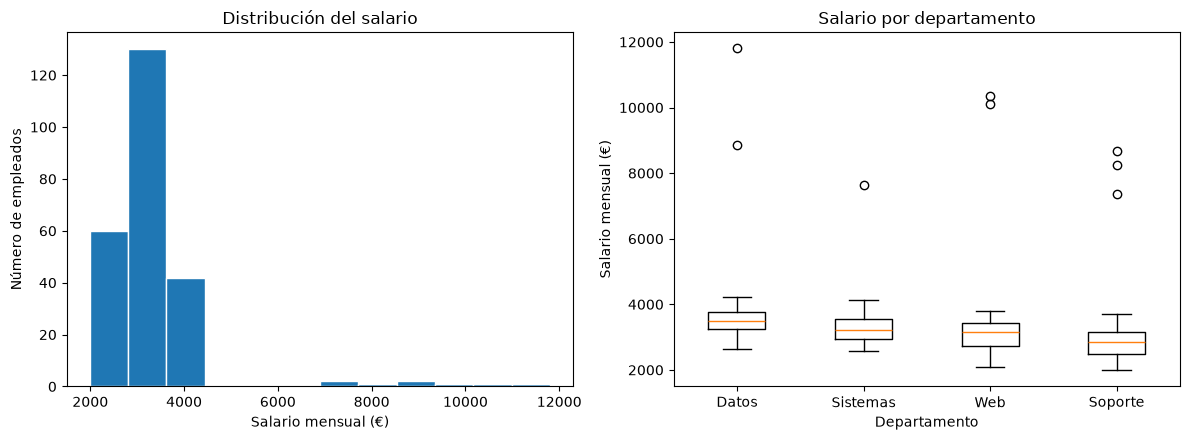

In [6]:
nombres = ['Datos', 'Sistemas', 'Web', 'Soporte']
grupos = [empleados.loc[empleados['departamento'] == d, 'salario'] for d in nombres]

fig_distribucion, axs_distribucion = plt.subplots(1, 2, figsize=(12, 4.5))
axs_distribucion[0].hist(empleados['salario'], bins=12, density=False, edgecolor='white')
axs_distribucion[0].set_title('Distribución del salario')
axs_distribucion[0].set_xlabel('Salario mensual (€)')
axs_distribucion[0].set_ylabel('Número de empleados')

axs_distribucion[1].boxplot(grupos)
axs_distribucion[1].set_xticks(range(1, len(nombres) + 1))
axs_distribucion[1].set_xticklabels(nombres)
axs_distribucion[1].set_title('Salario por departamento')
axs_distribucion[1].set_xlabel('Departamento')
axs_distribucion[1].set_ylabel('Salario mensual (€)')
plt.tight_layout()
plt.show()


In [7]:
assert len(grupos) == 4
assert len(axs_distribucion) == 2
assert len(axs_distribucion[0].patches) >= 1
assert len(axs_distribucion[1].lines) >= 1
print('Situación 3: comprobación superada')

Situación 3: comprobación superada


## Situación 4 — Experiencia y salario

**Pregunta:** ¿la experiencia se asocia con un salario mayor?

**Tarea:** crea `fig_relacion, ax_relacion = plt.subplots(...)`. Dibuja una dispersión de `experiencia` frente a `salario`, con `alpha` y color según la experiencia; añade una colorbar. Calcula `maximo = empleados.loc[empleados['salario'].idxmax()]`, anótalo con `annotate` y añade una línea horizontal con la mediana.

**Salida esperada:** asociación positiva, mucha dispersión y un salario máximo por encima de 10.000 €. La asociación no demuestra causalidad.


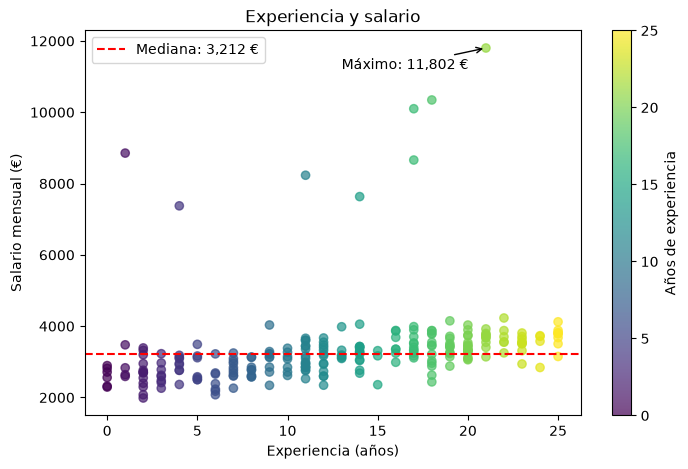

In [8]:
fig_relacion, ax_relacion = plt.subplots(figsize=(8, 5))
sc = ax_relacion.scatter(empleados['experiencia'], empleados['salario'],
                         c=empleados['experiencia'], cmap='viridis', alpha=0.7)
fig_relacion.colorbar(sc, ax=ax_relacion, label='Años de experiencia')

maximo = empleados.loc[empleados['salario'].idxmax()]
mediana_sal = empleados['salario'].median()
ax_relacion.annotate(f"Máximo: {maximo['salario']:,.0f} €",
                     xy=(maximo['experiencia'], maximo['salario']),
                     xytext=(maximo['experiencia'] - 8, maximo['salario'] * 0.95),
                     arrowprops=dict(arrowstyle='->'))
ax_relacion.axhline(mediana_sal, color='red', linestyle='--', label=f'Mediana: {mediana_sal:,.0f} €')
ax_relacion.set_title('Experiencia y salario')
ax_relacion.set_xlabel('Experiencia (años)')
ax_relacion.set_ylabel('Salario mensual (€)')
ax_relacion.legend()
plt.show()


In [9]:
assert maximo['salario'] > 10000
assert len(fig_relacion.axes) >= 2
assert len(ax_relacion.collections) >= 1
print('Situación 4: comprobación superada')

Situación 4: comprobación superada


## Situación 5 — Panel y recomendación

**Tarea:** crea `fig_panel, axs_panel = plt.subplots(2, 2, ...)` con los cuatro gráficos: líneas, barras, histograma y dispersión. Añade títulos y unidades; no compartas ejes de magnitudes distintas. Anota el máximo y la mediana en la dispersión.

Guarda **antes de** `plt.show()`:

- `salidas_estaticas/panel_personal.png` con `dpi=150` y `bbox_inches='tight'`.
- `salidas_estaticas/panel_personal.svg` con `bbox_inches='tight'`.

Después escribe en una celda Markdown: tres frases (qué muestra cada bloque, qué no permite concluir) y una recomendación para la dirección.


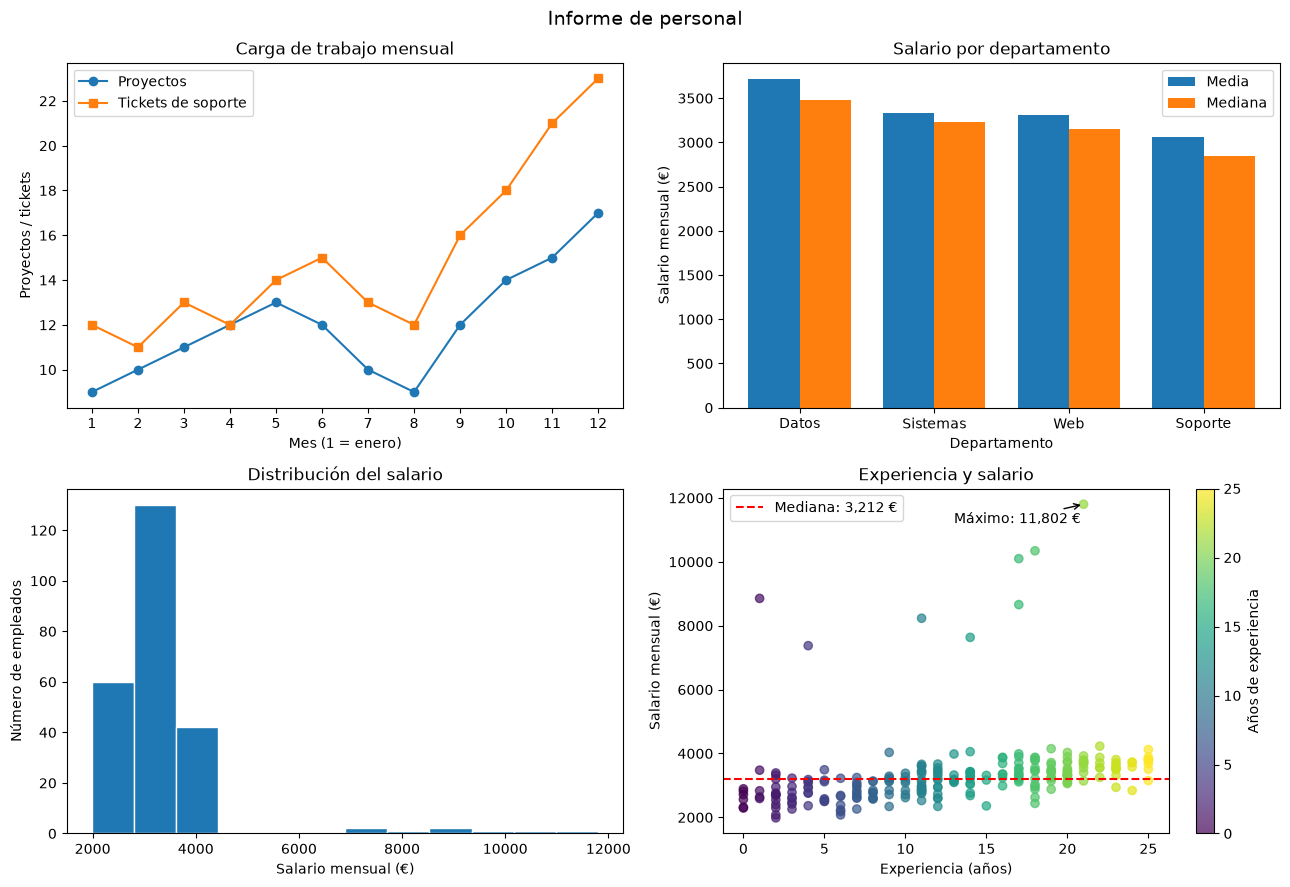

In [10]:
fig_panel, axs_panel = plt.subplots(2, 2, figsize=(13, 9))

# Líneas
ax = axs_panel[0, 0]
ax.plot(mensual['mes'], mensual['proyectos'], marker='o', label='Proyectos')
ax.plot(mensual['mes'], mensual['soporte'], marker='s', label='Tickets de soporte')
ax.set_xticks(mensual['mes'])
ax.set_title('Carga de trabajo mensual')
ax.set_xlabel('Mes (1 = enero)')
ax.set_ylabel('Proyectos / tickets')
ax.legend()

# Barras
ax = axs_panel[0, 1]
ax.bar(x - ancho / 2, medias.values, ancho, label='Media')
ax.bar(x + ancho / 2, medianas.values, ancho, label='Mediana')
ax.set_xticks(x)
ax.set_xticklabels(orden)
ax.set_title('Salario por departamento')
ax.set_xlabel('Departamento')
ax.set_ylabel('Salario mensual (€)')
ax.legend()

# Histograma
ax = axs_panel[1, 0]
ax.hist(empleados['salario'], bins=12, edgecolor='white')
ax.set_title('Distribución del salario')
ax.set_xlabel('Salario mensual (€)')
ax.set_ylabel('Número de empleados')

# Dispersión
ax = axs_panel[1, 1]
sc = ax.scatter(empleados['experiencia'], empleados['salario'],
                c=empleados['experiencia'], cmap='viridis', alpha=0.7)
fig_panel.colorbar(sc, ax=ax, label='Años de experiencia')
ax.annotate(f"Máximo: {maximo['salario']:,.0f} €",
            xy=(maximo['experiencia'], maximo['salario']),
            xytext=(maximo['experiencia'] - 8, maximo['salario'] * 0.95),
            arrowprops=dict(arrowstyle='->'))
ax.axhline(mediana_sal, color='red', linestyle='--', label=f'Mediana: {mediana_sal:,.0f} €')
ax.set_title('Experiencia y salario')
ax.set_xlabel('Experiencia (años)')
ax.set_ylabel('Salario mensual (€)')
ax.legend()

fig_panel.suptitle('Informe de personal', fontsize=14)
fig_panel.tight_layout()
fig_panel.savefig(salida / 'panel_personal.png', dpi=150, bbox_inches='tight')
fig_panel.savefig(salida / 'panel_personal.svg', bbox_inches='tight')
plt.show()


In [11]:
assert len(fig_panel.axes) >= 4
assert (salida / 'panel_personal.png').exists()
assert (salida / 'panel_personal.svg').exists()
print('Situación 5: comprobación superada')

Situación 5: comprobación superada


## Interpretación

Escribe aquí, en tres frases:

1. Qué muestra cada bloque del panel.
2. Qué **no** permite concluir (por ejemplo, causalidad o generalización).
3. Una recomendación para la dirección, apoyada en una evidencia concreta.

**Respuesta:**

1. El panel muestra que la carga de trabajo crece durante el año (los proyectos pasan de 9 a 17 y los tickets de soporte de 12 a 23), que Datos tiene el salario más alto (mediana ≈ 3.484 €) y Soporte el más bajo (≈ 2.844 €), que los salarios se concentran en un rango con unos pocos valores extremos, y que la experiencia se asocia de forma positiva pero débil con el salario (correlación ≈ 0,28).
2. No permite concluir que la experiencia cause un salario mayor, ni generalizar a otras empresas, porque son datos sintéticos de 240 empleados, y tampoco sabemos si los 8 salarios extremos (el máximo ronda los 11.800 €) son errores o casos legítimos.
3. Recomiendo que la dirección use la mediana y no la media para revisar la política salarial, porque en Datos la media (≈ 3.715 €) supera a la mediana en unos 230 € por los extremos, y que refuerce Soporte antes de fin de año, ya que sus tickets casi se duplican y las horas extra pasan de 6 a 22.

## Reto opcional

Si terminas antes:

- Compara la media y la mediana **sin los salarios extremos** y explica qué cambia.
- Busca un gráfico engañoso (ejes truncados, tarta con demasiadas categorías, línea para categorías) y describe cómo lo corregirías.
- Añade al panel una comparación de `horas_semana` por departamento.

No es obligatorio para la entrega base.

**Respuestas:**

1. **Sin salarios extremos.** Excluyo los 8 salarios por encima del límite del boxplot (≈ 4.633 €). Las medias bajan y se acercan a las medianas: en Datos la media pasa de ≈ 3.715 € a ≈ 3.487 €, casi igual a su mediana (≈ 3.473 €), que apenas cambia. Esto confirma que la media es sensible a los extremos y la mediana es robusta.
2. **Gráfico engañoso.** Un gráfico de barras con el eje Y truncado, por ejemplo empezando en 2.000 €, exagera las diferencias entre departamentos. Lo corregiría empezando el eje en 0 o, si hay que truncarlo, indicándolo claramente en el eje y en el título.
3. **Horas semanales por departamento.** Las medias son casi idénticas (≈ 39,5 a 39,7 h), así que el departamento no explica diferencias en horas trabajadas. La mayor carga de Soporte se ve en los tickets y las horas extra mensuales, no en las horas semanales.

## Ticket de salida

Responde en dos o tres líneas cada pregunta:

1. ¿Qué gráfico usaste para cada situación y por qué?
2. ¿Qué diferencia hay entre barras e histograma?
3. ¿Qué le hacen los valores extremos a la media? ¿Y a la mediana?
4. ¿Puedes afirmar que la experiencia **causa** un salario mayor? ¿Qué puedes decir?
5. ¿Qué diferencia hay entre `fig` y `ax`?
6. ¿Qué recomendación darías y con qué limitación?

**Respuestas:**

1. En la situación 1 usé líneas, porque el tiempo es continuo y interesa ver la tendencia. En la 2 usé barras agrupadas, para comparar media y mediana entre departamentos, que son categorías. En la 3 usé histograma y boxplot, para ver la distribución del salario y los valores extremos. En la 4 usé dispersión, para relacionar dos variables numéricas (experiencia y salario).
2. Las barras comparan categorías separadas y su orden es libre. El histograma agrupa una variable numérica continua en intervalos, con las barras pegadas, y la altura indica cuántos datos caen en cada intervalo.
3. Los valores extremos tiran de la media hacia ellos y la desplazan. La mediana apenas cambia, porque solo depende de la posición central de los datos. En Datos, por ejemplo, la media (≈ 3.715 €) supera a la mediana (≈ 3.484 €) por los extremos.
4. No puedo afirmar que la experiencia cause un salario mayor, porque la correlación es débil (≈ 0,28) y puede haber otros factores, como el departamento. Puedo decir que existe una asociación positiva, con mucha dispersión.
5. `fig` es la figura completa, el lienzo que contiene todo y que se guarda con `savefig`. `ax` es un gráfico concreto dentro de la figura, con sus ejes, título y datos. Una figura puede tener varios `ax`.
6. Recomiendo basar la política salarial en medianas y reforzar Soporte, porque sus tickets pasan de 12 a 23 y las horas extra de 6 a 22 a lo largo del año. La limitación es que los datos son sintéticos y de un solo año, así que no permiten generalizar.

## Registro de entrega

| Apartado | Completo / en curso / pendiente | Qué he probado o qué falta |
|---|---|---|
| Preparación del entorno | Completo | Ejecuté la celda de datos: 240 empleados, 12 meses y 12 ausentes en `satisfaccion`; los tres `assert` pasan. |
| Situación 1: líneas | Completo | Dos series con marcadores distintos, leyenda y ejes con unidades; el máximo de soporte es en diciembre y el `assert` pasa. |
| Situación 2: barras e histograma | Completo | Barras agrupadas de media y mediana por departamento; Datos tiene la mediana más alta y el `assert` pasa. |
| Situación 3: cajas y outliers | Completo | Histograma con `bins=12` y boxplot de cuatro cajas con puntos por encima de los bigotes; el `assert` pasa. |
| Situación 4: dispersión | Completo | Dispersión con colorbar, máximo anotado (> 10.000 €) y línea de mediana; el `assert` pasa. |
| Situación 5: panel y exportación | Completo | Panel 2×2 guardado como PNG y SVG en `salidas_estaticas/`; el `assert` pasa. |
| Interpretación y recomendación | Completo | Tres frases en la interpretación y respuestas del ticket, con cifras tomadas de mis datos (semilla 42). |

**Ayuda utilizada (documentación, pareja, IA):** Usé IA para correcciones de errores y errores sintácticos, mis compañeros me ayudaron en algún ejercicio en un caso espontáneo

**Antes de entregar:** reinicia el kernel y ejecuta tus celdas en orden; conserva las salidas. Comprueba la estructura del ZIP en [caso-informe-personal.md](caso-informe-personal.md). Si queda algo pendiente, regístralo y no lo marques como completo.
